In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル・開発環境で実行中。リポジトリルート:", repo_root)


💻 ローカル・開発環境で実行中。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 7.2 割り込みハンドラ (`Interrupt Handlers & Compiler Attribute`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/7/7.2_Interrupt_Handlers_and_Compiler_Attribute.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.10%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20UEFI-orange.svg)
![Status](https://img.shields.io/badge/Status-Completed-brightgreen.svg)

---

## 📖 本節の概要と学習目標

前節（7.1節）では、ポーリング方式の CPU 資源浪費問題とハードウェア割り込み（*Hardware Interrupt*）によるイベント駆動制御の原理、および CPU の自動スタック退避構造について学びました。

本節（7.2節）では、CPU が割り込みを受け付けた際に実行する特別なルーチンである **「割り込みハンドラ (*Interrupt Handler / ISR: Interrupt Service Routine*)」** の C++ 実装方法を徹底解剖します。一見すると単なる C/C++ 関数のように思えますが、割り込みハンドラは **「通常の関数とは全く異なるハードウェア・ABI の制約」** の下で動作します。

> [!IMPORTANT]
> **本節で解き明かす 5 大テーマ**:
> 1. **なぜ通常関数をそのまま割り込みハンドラにしてはいけないのか？**: System V AMD64 ABI におけるレジスタ保護規則（Caller-saved vs Callee-saved）と非同期割り込みによるレジスタ破壊バグの危険性
> 2. **スタックフレーム `InterruptFrame` のメモリ構造**: CPU ハードウェアが割り込み発生時に自動退避する 5 つの 64 ビット値（`RIP`, `CS`, `RFLAGS`, `RSP`, `SS`）の物理レイアウト
> 3. **16 バイトスタックアライメントの罠**: なぜ x86-64 ではスタックが 16 バイト境界に整列していなければならないのか？（SSE/AVX `movaps` 命令による `#GP` 一般保護例外の回避）
> 4. **コンパイラ拡張 `__attribute__((interrupt))` の魔法**: GCC / Clang が全レジスタ退避プロローグ・16Bアライメント調整・エピローグ・`IRETQ` 命令を全自動生成する仕組み
> 5. **MikanOS での実装**: `kernel/interrupt.hpp` のデータ構造定義と `IntHandlerXHCI`（ベクタ 0x40）の処理フロー

### 専門用語・英語略語一覧
- **ISR**: *Interrupt Service Routine*（割り込みサービスルーチン / 割り込みハンドラ）
- **System V AMD64 ABI**: Linux やベアメタル OS が標準採用する x86-64 向け関数呼び出し規約
- **Caller-saved Registers**: 呼び出し側退避レジスタ（揮発性スクラッチレジスタ: `RAX`, `RCX`, `RDX`, `RSI`, `RDI`, `R8`〜`R11`）
- **Callee-saved Registers**: 被呼び出し側退避レジスタ（不揮発性レジスタ: `RBX`, `RBP`, `R12`〜`R15`）
- **InterruptFrame**: ハードウェアがスタックへ自動プッシュする 5 つのコンテキスト値（40 バイト）
- **IRETQ**: *Interrupt Return 64-bit*（スタックから 5 レジスタを不可分に復元して被割り込みコードへ戻る 64 ビット命令）
- **EOI**: *End of Interrupt*（Local APIC に割り込み処理完了を通知する信号）


---

## 1. 割り込みハンドラとは何か？（通常関数との決定的な違い）

### 1.1 「非同期呼び出し」の恐怖

通常の C/C++ プログラムにおける関数呼び出しは、プログラマが意図した場所で明示的に `foo()` を呼ぶことで、アセンブリの `CALL` 命令が発行されます。呼び出し元コードは「今から関数を呼ぶ」と事前に分かっているため、必要なデータを退避しておくことができます。

しかし、**割り込みハンドラ（ISR）はハードウェアから非同期（*Asynchronous*）に強制起動**されます。
- CPU がユーザープログラムを実行していようが、カーネルの別のループを回していようが、演算命令の合間に突然割り込みが入ります。
- 被割り込み側（割り込まれたコード）は、「いつ割り込まれたか」を知る由もありません。

### 1.2 System V AMD64 ABI のレジスタ保護規則とレジスタ破壊ハザード

x86-64 の System V AMD64 ABI では、16 個の汎用レジスタが以下のように役割分担されています：

| 分類 | レジスタ名 | 役割と保護規則 |
|---|---|---|
| **Caller-saved**<br>(呼び出し側退避 / 揮発性) | `RAX`, `RCX`, `RDX`, `RSI`, `RDI`,<br>`R8`, `R9`, `R10`, `R11` | 関数内部で**自由に変更（破壊）してよい**。<br>関数の呼び出し側が必要なら自分でスタックに保存する義務がある。 |
| **Callee-saved**<br>(被呼び出し側退避 / 不揮発性) | `RBX`, `RBP`, `R12`, `R13`, `R14`, `R15` | 関数内部で値を変更する場合、**関数側（Callee）が必ず PUSH/POP で元の値を復元**して戻らなければならない。 |
| **特殊レジスタ** | `RSP`, `RIP`, `RFLAGS` | スタックポインタ、命令ポインタ、CPUステータスフラグ |

> [!CAUTION]
> **通常の C++ 関数を割り込みハンドラとして登録すると何が起きるか？**
> 通常の関数としてコンパイルされたコードは、Caller-saved レジスタ（`RAX`, `RDX` など）を「自由に変更してよい領域」とみなして遠慮なく上書きします。
> もしメイン処理が `RAX` を使って重要なポインタ計算を行っている最中に割り込みが発生し、通常関数のハンドラが `RAX` を上書きして `RET` してしまうと、**メイン処理に戻った瞬間に `RAX` の値が破壊されており、誤ったメモリアクセスや未定義動作（カーネルパニック）を引き起こします**！

したがって、**割り込みハンドラは、使用するすべてのレジスタ（Caller-saved 含む全レジスタ）をスタックへ確実に退避・復元しなければならない**という絶対的な鉄則が存在します。


---

## 2. 通常関数呼び出し (`CALL`/`RET`) vs 割り込みハンドラ (`IRETQ`)

スタックの挙動と復帰命令においても、通常関数と割り込みハンドラには根本的な違いがあります。

### 2.1 通常関数のスタック遷移 (`CALL` / `RET`)
- `CALL <func>` 命令:
  1. 次の命令のアドレス（戻り先 `RIP`: 8 バイト）をスタックへ PUSH: `RSP = RSP - 8`
  2. `RIP = <func>` へジャンプ
- `RET` 命令:
  1. スタックから 8 バイトを POP して `RIP` に格納: `RSP = RSP + 8`
  2. ※ `RFLAGS`（フラグ）やセグメントセレクタ（`CS`, `SS`）は一切復元されません。

### 2.2 割り込み発生時の CPU ハードウェア自動スタック退避 (`IRETQ`)
CPU は割り込み信号を受信すると、ソフトウェア命令の介在なしに、**ハードウェア回路自身が以下の 5 つの 64 ビット値をスタックへ自動プッシュ**します（計 40 バイト）：

$$\begin{aligned}
\text{RSP} &\leftarrow \text{RSP} - 8, \quad [\text{RSP}] \leftarrow \text{SS} & \text{(割り込み前のスタックセグメント)} \\
\text{RSP} &\leftarrow \text{RSP} - 8, \quad [\text{RSP}] \leftarrow \text{RSP}_{\text{old}} & \text{(割り込み前のスタックポインタ)} \\
\text{RSP} &\leftarrow \text{RSP} - 8, \quad [\text{RSP}] \leftarrow \text{RFLAGS} & \text{(割り込み前のフラグレジスタ)} \\
\text{RSP} &\leftarrow \text{RSP} - 8, \quad [\text{RSP}] \leftarrow \text{CS} & \text{(割り込み前のコードセグメント)} \\
\text{RSP} &\leftarrow \text{RSP} - 8, \quad [\text{RSP}] \leftarrow \text{RIP} & \text{(割り込み前の次に実行する命令アドレス)}
\end{aligned}$$

そして、割り込みハンドラの終了時には通常の `RET` ではなく、**`IRETQ` (*Interrupt Return 64-bit*) 命令** を実行します。
- `IRETQ` はスタックから `RIP`, `CS`, `RFLAGS`, `RSP`, `SS` を順番に POP して元のレジスタへ不可分（アトミック）に復元します。
- これにより、割り込み前のフラグ状態（`IF` 割り込み許可フラグなど）やスタックポインタが完全に元通りに修復されます。


---

## 3. スタック構造とレジスタ退避の完全対比図 (Figure 7.03)

通常関数のスタック遷移と割り込みハンドラのスタック構造の差異を、高解像度図版（Figure 7.03）として可視化・検証します。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24424: UserWarning: Glyph 12304 (\N{LEFT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24424: UserWarning: Glyph 36890 (\N{CJK UNIFIED IDEOGRAPH-901A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24424: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24424: UserWarning: Glyph 38306 (\N{CJK UNIFIED IDEOGRAPH-95A2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24424: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24424: UserWarning: Glyph

✅ Figure 7.03 を生成・保存しました: /home/student/Documents/GitHub/study-mikanos/7/result/fig7_03_regular_call_vs_interrupt_stack.png


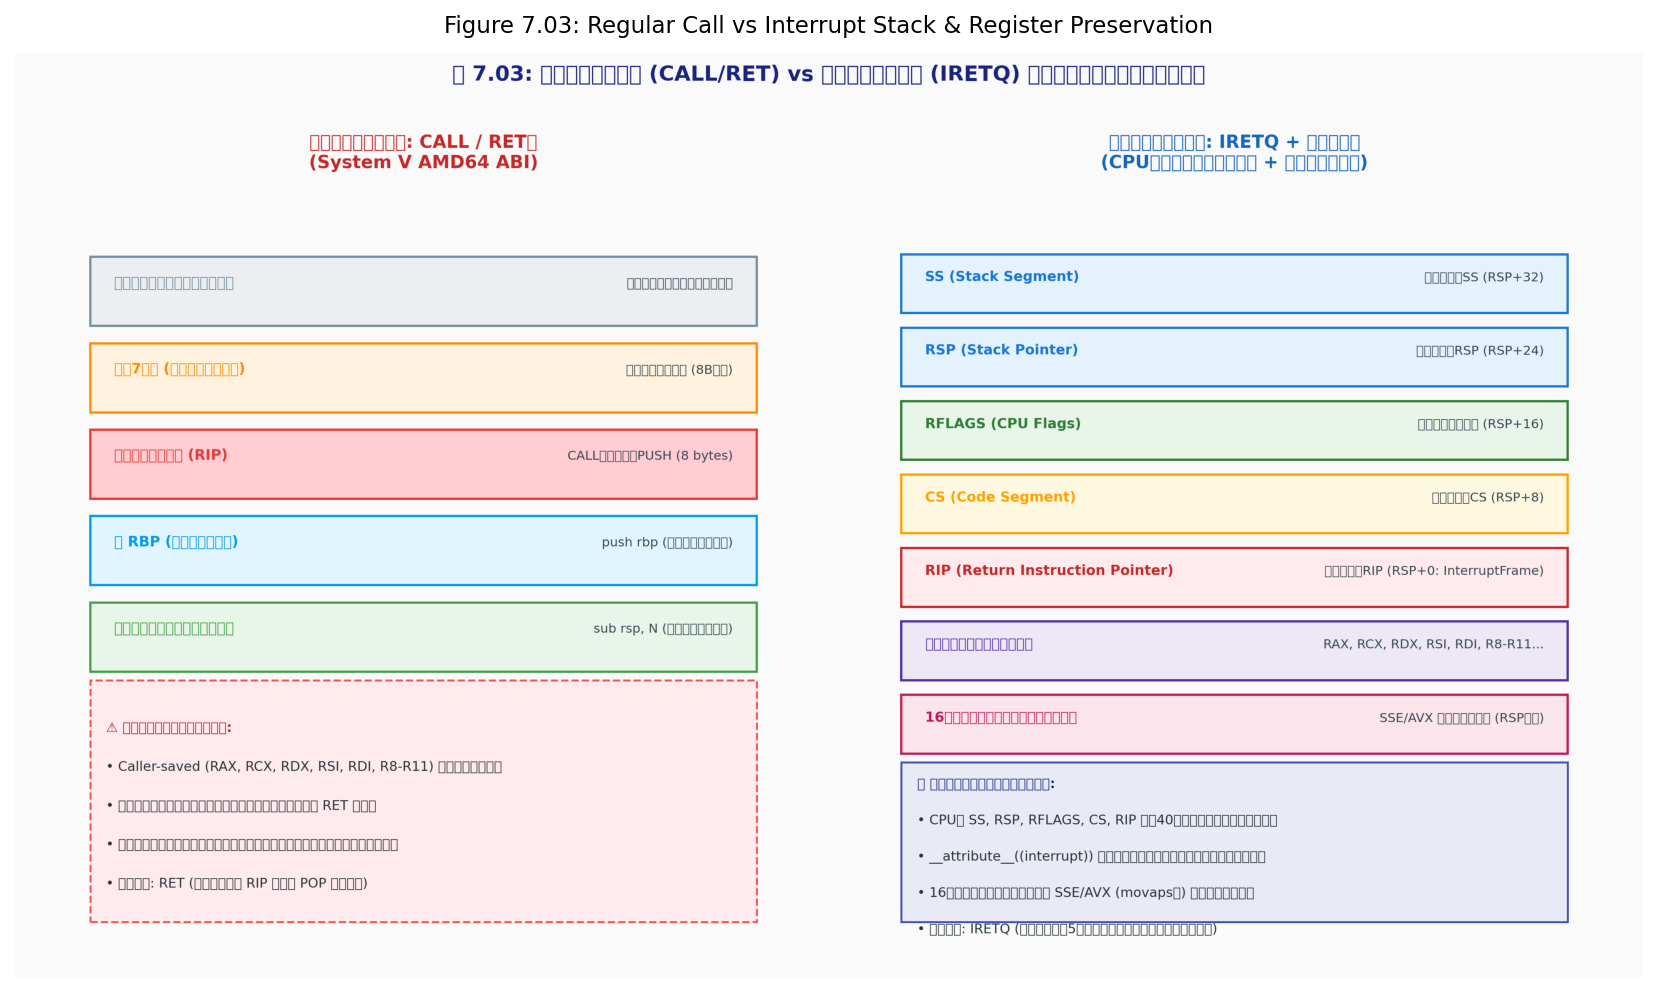

In [2]:
# === Figure 7.03: 通常関数呼び出し vs 割り込みハンドラのスタック・レジスタ保護対比 ===
import os
import matplotlib.pyplot as plt
from common import plot_regular_call_vs_interrupt_stack

fig_path = os.path.join(repo_root, "7", "result", "fig7_03_regular_call_vs_interrupt_stack.png")
plot_regular_call_vs_interrupt_stack(fig_path)
print(f"✅ Figure 7.03 を生成・保存しました: {fig_path}")

img = plt.imread(fig_path)
plt.figure(figsize=(14, 8), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 7.03: Regular Call vs Interrupt Stack & Register Preservation", fontsize=11, pad=10)
plt.show()


---

## 4. x86-64 スタックフレーム `InterruptFrame` と 16 バイトアライメント

### 4.1 MikanOS における `InterruptFrame` 構造体定義

MikanOS では、ハードウェアが自動的にプッシュしたスタック上の 40 バイトの構造を `kernel/interrupt.hpp` において以下のように定義しています：

```cpp
// kernel/interrupt.hpp
struct InterruptFrame {
  uint64_t rip;    // [RSP + 0]  割り込み発生時に次に実行するはずだった命令ポインタ
  uint64_t cs;     // [RSP + 8]  コードセグメントセレクタ (0x0008)
  uint64_t rflags; // [RSP + 16] 割り込み前の CPU フラグレジスタ
  uint64_t rsp;    // [RSP + 24] 割り込み前のスタックポインタ
  uint64_t ss;     // [RSP + 32] スタックセグメントセレクタ (0x0020)
};
```

スタックは「低位アドレスへ向かって成長」するため、ハードウェアが最後にプッシュした `RIP` が最も低位のアドレス（現在の `RSP`）になります。したがって、ハンドラ関数の第1引数 `InterruptFrame* frame` はまさに `[RSP + 0]` のメモリアドレスを指すことになります。

### 4.2 16 バイトスタックアライメントの罠（SSE/AVX クラッシュ防止）

System V AMD64 ABI には **「関数呼び出し直後のスタックポインタ `RSP` は 16 バイト境界に整列していなければならない」** という厳格な規約があります。

> [!WARNING]
> **なぜ 16 バイトアライメントが必要なのか？**
> 現代の C++ コンパイラは、`memcpy` やローカル変数の初期化・ベクター演算に **SSE / AVX 命令（`movaps`, `movdqa` 等）** を自動生成します。これらの命令は、対象メモリアドレスが 16 バイト境界（アドレスの下位 4 ビットが `0x0`）でない場合、CPU ハードウェアが **`#GP` (一般保護例外, General Protection Exception)** を発生させてシステムが即死します。

ここで数学的なアライメントの計算を行ってみましょう：
- 割り込み発生前のタスクのスタックポインタが 16 バイト境界であったと仮定します: $\text{RSP}_{\text{before}} \equiv 0 \pmod{16}$
- CPU ハードウェアが `InterruptFrame`（5 個の 64 ビット値 = 40 バイト）をプッシュします：
  $$\text{RSP}_{\text{after\_hw}} = \text{RSP}_{\text{before}} - 40$$
- このときの剰余を計算すると：
  $$-40 \equiv -40 + 48 = 8 \pmod{16}$$
- なんと、**ハードウェアプッシュ直後の `RSP` は必ず 16 バイト境界から 8 バイトずれてしまう**のです！

このため、割り込みハンドラのプロローグでは、スタックを再び 16 バイト境界へ補正する調整コード（`sub rsp, 8` 等）を適切に挿入する必要があります。


---

## 5. コンパイラ拡張 `__attribute__((interrupt))` の魔法

### 5.1 昔ながらの手法（アセンブリラッパースタブ）との対比

従来の OS 自作では、割り込みハンドラを C/C++ で書く場合、以下のようなアセンブリスタブ（`asmfunc.asm`）をハンドラごとに手書きする必要がありました：
```nasm
; 従来のアセンブリラッパーの例
IntHandlerWrapper:
    push rax
    push rcx
    ; ... 汎用レジスタ全15個を1つずつ push ...
    mov rdi, rsp           ; 第1引数にスタックフレームポインタを設定
    cld
    call CppIntHandler     ; C++ の本体関数を呼び出し
    ; ... 全レジスタを1つずつ pop ...
    iretq                  ; 割り込みから復帰
```
この方法では、割り込みの数だけアセンブリのラッパーを書く必要があり、保守性が著しく低下します。

### 5.2 `__attribute__((interrupt))` による完全自動化

GCC 7 および Clang 3.9 以降では、**`__attribute__((interrupt))`** という強力なコンパイラ属性がサポートされました！
関数宣言にこの属性を付加するだけで、コンパイラが以下のすべてを自動的に機械語展開してくれます：

1. **プロローグ**: `cld`（方向フラグクリア）、ハンドラ内部で使用される全汎用レジスタ（Caller-saved 含む）のスタック退避、および 16 バイトスタックアライメント調整
2. **第1引数渡し**: スタック上の `InterruptFrame` の先頭アドレスを自動的に引数 `frame` に束縛
3. **エピローグ**: 16 バイトスタックアライメント調整の復元、退避した全レジスタの逆順 POP
4. **復帰**: `ret` ではなく **`iretq` 命令** を自動発行！

```cpp
// MikanOS における記述例 (kernel/main.cpp)
__attribute__((interrupt))
void IntHandlerXHCI(InterruptFrame* frame) {
    // 通常の C++ コードをそのまま記述可能！
    // コンパイラが安全なプロローグ・エピローグを全自動生成
    while (xhc->PrimaryEventRing()->HasFront()) {
        ProcessEvent(*xhc);
    }
    NotifyEndOfInterrupt();
}
```


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24531: UserWarning: Glyph 12304 (\N{LEFT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24531: UserWarning: Glyph 12364 (\N{HIRAGANA LETTER GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24531: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24531: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24531: UserWarning: Glyph 12377 (\N{HIRAGANA LETTER SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24531: UserWarning: Glyph 12427 (\N{HIRAG

✅ Figure 7.04 を生成・保存しました: /home/student/Documents/GitHub/study-mikanos/7/result/fig7_04_compiler_attribute_interrupt_mechanism.png


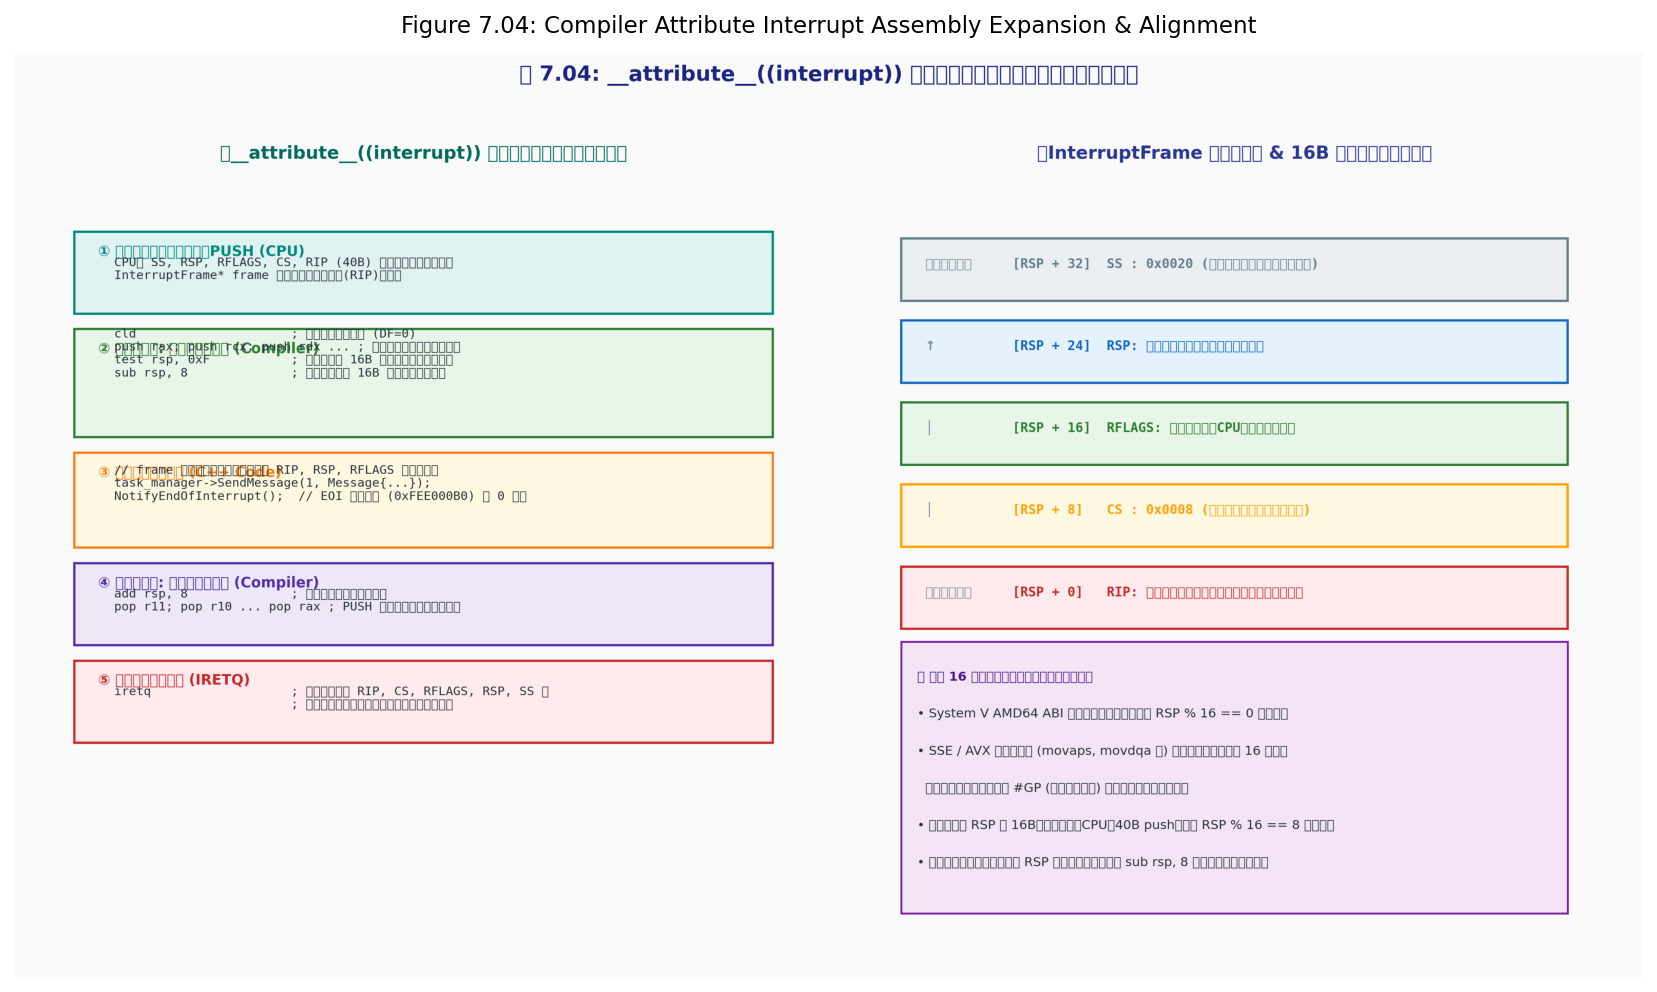

In [3]:
# === Figure 7.04: __attribute__((interrupt)) の内部動作メカニズム & アセンブリ展開 ===
import os
import matplotlib.pyplot as plt
from common import plot_compiler_attribute_interrupt_mechanism

fig_path2 = os.path.join(repo_root, "7", "result", "fig7_04_compiler_attribute_interrupt_mechanism.png")
plot_compiler_attribute_interrupt_mechanism(fig_path2)
print(f"✅ Figure 7.04 を生成・保存しました: {fig_path2}")

img2 = plt.imread(fig_path2)
plt.figure(figsize=(14, 8), dpi=150)
plt.imshow(img2)
plt.axis("off")
plt.title("Figure 7.04: Compiler Attribute Interrupt Assembly Expansion & Alignment", fontsize=11, pad=10)
plt.show()


---

## 6. MikanOS での割り込みハンドラ実装 (`osbook_day07a`)

### 6.1 `IntHandlerXHCI` と EOI の役割

`osbook_day07a` 時点での `kernel/main.cpp` における xHCI 割り込みハンドラは以下のように実装されています：

```cpp
// kernel/main.cpp
usb::xhci::Controller* xhc;

__attribute__((interrupt))
void IntHandlerXHCI(InterruptFrame* frame) {
  while (xhc->PrimaryEventRing()->HasFront()) {
    if (auto err = ProcessEvent(*xhc)) {
      Log(kError, "Error while ProcessEvent: %s at %s:%d\n",
          err.Name(), err.File(), err.Line());
    }
  }
  NotifyEndOfInterrupt();
}
```

### 6.2 なぜ EOI (End of Interrupt) 通知が必要なのか？

`NotifyEndOfInterrupt()` 関数（`kernel/interrupt.cpp`）の中身を見てみましょう：

```cpp
// kernel/interrupt.cpp
void NotifyEndOfInterrupt() {
  volatile auto end_of_interrupt = reinterpret_cast<uint32_t*>(0xfee000b0);
  *end_of_interrupt = 0;
}
```

- `0xfee000b0` は、CPU 内蔵の **Local APIC (Advanced Programmable Interrupt Controller)** の **EOI レジスタ** の物理アドレスです。
- Local APIC は、CPU が割り込み処理中であることを内部の ISR (*In-Service Register*) ビットで追跡しています。
- ハンドラ終了時に EOI レジスタへ `0` を書き込まないと、Local APIC は「前の割り込みがまだ終わっていない」と判断し、**次以降の同等・低優先度の割り込みをすべてブロック（無視）してしまいます**！
- したがって、割り込みハンドラの末尾で EOI を発行することは、割り込み機構を維持するための必須要件です。


---

## 7. C++20 スタンドアロン検証コードによるメモリ構造 & レジスタ保護の実証

`src/ch07/interrupt_handler_sim.cpp` をコンパイル・実行し、以下を対話的に実証します：
1. `InterruptFrame` の 40 バイトメモリレイアウトおよび各メンバーのオフセット検証
2. 通常関数を割り込みハンドラにした際の Caller-saved レジスタ破壊の検出
3. `__attribute__((interrupt))` による全レジスタ保護とコンテキスト完全維持の実証
4. 16 バイトスタックアライメント遷移の数理検証


In [4]:
# === C++20 スタンドアロン検証コードのコンパイルと実行 ===
import subprocess, os

src_path = os.path.join(repo_root, "src/ch07/interrupt_handler_sim.cpp")
bin_path = os.path.join(repo_root, "src/ch07/interrupt_handler_sim")
cmd_compile = f"g++ -std=c++20 -O2 -Wall -Wextra -pedantic {src_path} -o {bin_path}"
res_c = subprocess.run(cmd_compile, shell=True, capture_output=True, text=True)
if res_c.returncode != 0:
    print("❌ コンパイル失敗:", res_c.stderr)
else:
    print("✅ C++20 検証コードのコンパイル成功!")
    res_r = subprocess.run(bin_path, shell=True, capture_output=True, text=True)
    print(res_r.stdout)


✅ C++20 検証コードのコンパイル成功!
🍊 MikanOS Ch 7.2: Interrupt Handlers & __attribute__((interrupt))

--- 1. InterruptFrame Memory Layout Verification ---
InterruptFrame Total Size: 40 bytes
  - offsetof(rip):    0 bytes
  - offsetof(cs):     8 bytes
  - offsetof(rflags): 16 bytes
  - offsetof(rsp):    24 bytes
  - offsetof(ss):     32 bytes
  ==> [PASS] InterruptFrame matches x86-64 hardware push specification!

--- 2. System V AMD64 ABI Register Classification ---
Caller-saved (scratch / non-preserved) registers: 9
Callee-saved (preserved) registers:               6
  ==> [PASS] Register classifications verified!

--- 3. Hazard: Regular C Function as Interrupt Handler ---
Context intact after regular ISR: NO (CORRUPTED)
Corrupted register count: 5
  - rax was silently overwritten without save/restore!
  - rcx was silently overwritten without save/restore!
  - rdx was silently overwritten without save/restore!
  - rsi was silently overwritten without save/restore!
  - rdi was silently overwritten

---

## 8. 本節のまとめと次節（7.3 割り込みベクタ）への展開

### 8.1 本節の総括まとめ

| 項目 | 通常の関数呼び出し (`CALL` / `RET`) | 割り込みハンドラ (`__attribute__((interrupt))` / `IRETQ`) |
|---|---|---|
| **呼び出し契機** | プログラムの意図したタイミング（明示的同期呼び出し） | ハードウェア・例外による非同期・強制呼び出し |
| **CPUスタック自動退避** | 戻り先 `RIP` のみ (8 bytes) | `SS`, `RSP`, `RFLAGS`, `CS`, `RIP` (40 bytes) |
| **レジスタ保護責任** | Callee-saved のみ保護。Caller-saved は破壊可能 | **全レジスタ保護必須**（コンパイラが自動退避・復元） |
| **スタックアライメント** | 呼び出し元が 16B 整列を維持 | プロローグで 16B 境界へ自動補正 (`sub rsp, 8` 等) |
| **復帰命令** | `RET` (スタックから RIP のみ POP) | **`IRETQ`** (スタックから 5 レジスタを不可分に復元) |
| **ハードウェア通知** | なし | **EOI (End of Interrupt)** を Local APIC へ通知 |

### 8.2 次節へのロードマップ

ハンドラ関数の準備が整いました。しかし、CPU は「マウスの割り込みが発生したときに、どのハンドラ関数を呼び出すべきか」をまだ知りません。
次節 **7.3「割り込みベクタ (Interrupt Vectors in x86-64)」** では：
- 0 〜 255 番の割り込みベクタ番号の体系（CPU 予約例外 vs ユーザー定義割り込み）
- MikanOS が xHCI 用に割り当てたベクタ番号 `0x40` の設計根拠
について掘り下げていきます。
